In [4]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 


In [5]:
from sklearn.datasets import fetch_california_housing

In [6]:
data=fetch_california_housing()

In [7]:
data

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [8]:
df=pd.DataFrame(data.data,columns= data.feature_names)
df['Price']=data.target

In [9]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [10]:
#multicollinearity >> when one fearure is explained by all other fearures (more than 2)
# when two features >> we use >> correlation 
# when more than two features >> here we use >> VIF>>variation infleton features and clustermap

<Axes: >

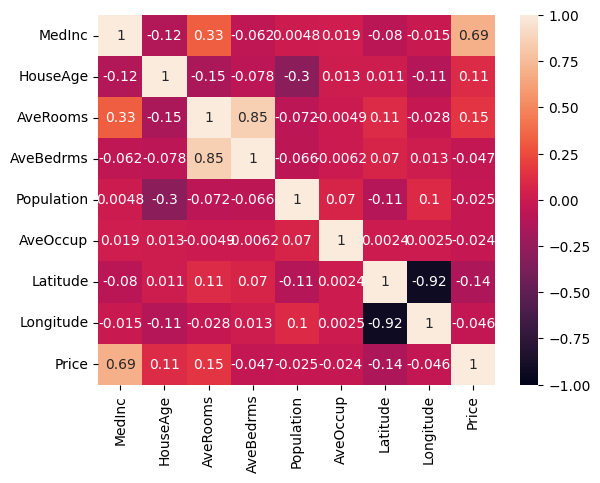

In [11]:
sns.heatmap(df.corr(),annot=True,vmin=-1,vmax=1)

<Figure size 500x500 with 0 Axes>

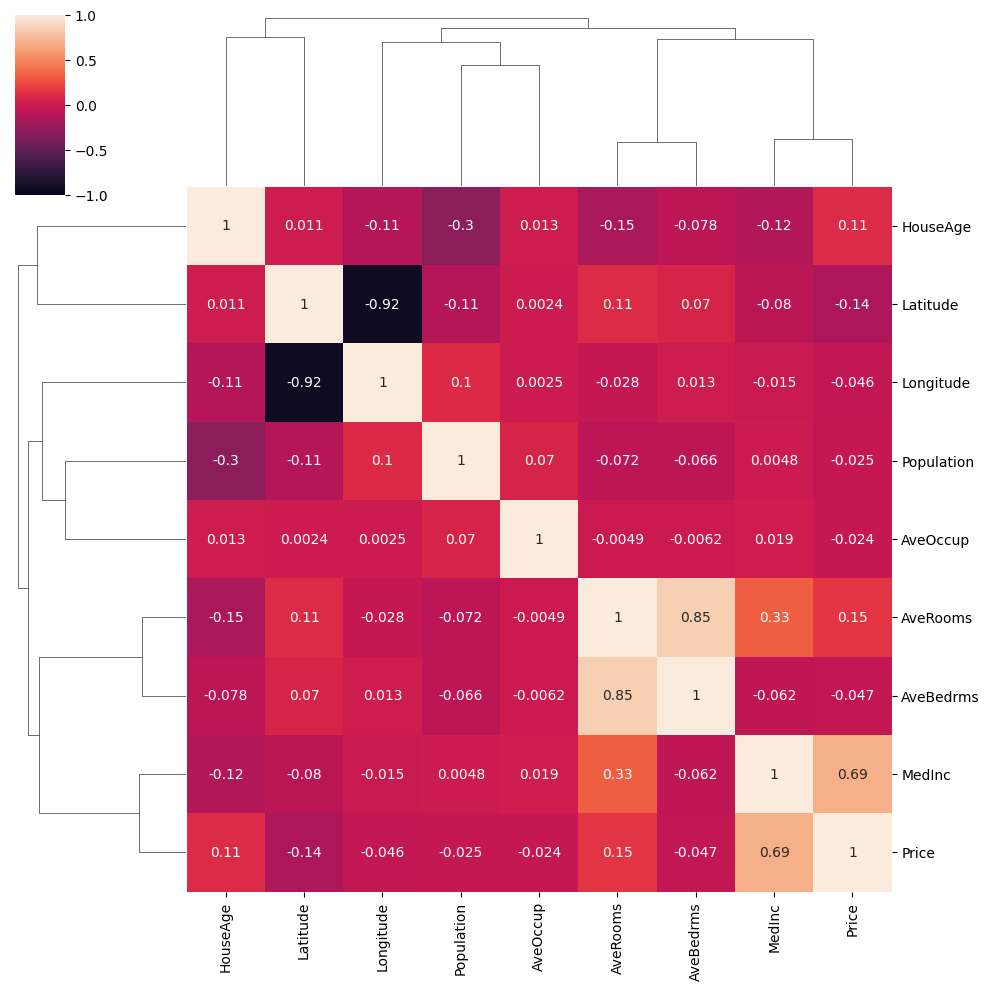

In [12]:
#clustermap table showa group(cluster) rel ationship

plt.figure(figsize=(5,5))
sns.clustermap(df.corr(),vmin=-1,vmax=1,annot=True)

In [17]:
#statsmodels is alibrary here we use statics tools 
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 6.4 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [18]:
from statsmodels.stats.outliers_influence import variance_inflation_factor



In [19]:
vif=pd.DataFrame()
vif['Feature']=df.columns

In [20]:
vif

,Feature
0,MedInc
1,HouseAge
2,AveRooms
3,AveBedrms
4,Population
5,AveOccup
6,Latitude
7,Longitude
8,Price


In [23]:
vif["VIF"]=[variance_inflation_factor(df.values,i) for i in range(len(df.columns))]

"""
df.values → converts DataFrame into a NumPy array.
i → represents each column/feature index.
range(len(df.columns)) → loops through all columns.
variance_inflation_factor(df.values, i) → calculates VIF for the i-th feature.
vif["VIF"] → stores all calculated VIF values in the VIF DataFrame column.
"""

'\ndf.values → converts DataFrame into a NumPy array.\ni → represents each column/feature index.\nrange(len(df.columns)) → loops through all columns.\nvariance_inflation_factor(df.values, i) → calculates VIF for the i-th feature.\nvif["VIF"] → stores all calculated VIF values in the VIF DataFrame column.\n'

In [ ]:
vif # After calculating the vif drop the heights feature  one by one 

,Feature,VIF
0,MedInc,3.813979
1,HouseAge,1.268150
2,AveRooms,8.477254
3,AveBedrms,7.173226
4,Population,1.138164
5,AveOccup,1.011274
6,Latitude,10.842087
7,Longitude,10.407641
8,Price,2.539571


In [25]:
df1=df.copy()

In [26]:
df1

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [27]:
#Now drop the heights feature longitude
df1.drop("Longitude",axis=1,inplace=True)

In [29]:
df1

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,3.422
...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,0.847


In [32]:
vif=pd.DataFrame()
vif['Feature']=df1.columns
vif["VIF"]=[variance_inflation_factor(df1.values,i) for i in range(len(df1.columns))]

In [33]:
vif

,Feature,VIF
0,MedInc,3.799267
1,HouseAge,1.218567
2,AveRooms,8.147959
3,AveBedrms,7.093147
4,Population,1.132336
5,AveOccup,1.011108
6,Latitude,1.073275
7,Price,2.186884


In [34]:
df1.drop("AveRooms",axis=1,inplace=True)

In [36]:
vif=pd.DataFrame()
vif["Feature"]=df1.columns
vif["VIF"]=[variance_inflation_factor(df.values,i) for i in range(len(df1.columns))]

In [37]:
vif

,Feature,VIF
0,MedInc,3.813979
1,HouseAge,1.268150
2,AveBedrms,8.477254
3,Population,7.173226
4,AveOccup,1.138164
5,Latitude,1.011274
6,Price,10.842087


In [41]:
X=df1.iloc[:,:-1]#independent variables
y=df1.iloc[:,-1]#dependent variable

In [44]:
from sklearn.model_selection import train_test_split

In [46]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.30,random_state=1)

In [47]:
X_train

,MedInc,HouseAge,AveBedrms,Population,AveOccup,Latitude
5748,2.9148,15.0,1.105532,3164.0,2.692766,34.16
5592,3.1779,41.0,1.054825,1658.0,3.635965,33.80
2110,2.5111,49.0,0.964361,1290.0,2.704403,36.75
13901,2.5405,15.0,1.422326,2568.0,2.388837,34.06
18425,4.5033,7.0,1.101173,1739.0,2.549853,37.26
...,...,...,...,...,...,...
10955,1.7823,17.0,1.087156,1079.0,2.474771,33.76
17289,8.5608,42.0,1.011538,753.0,2.896154,34.42
5192,1.1326,42.0,1.006826,775.0,2.645051,33.93
12172,2.6322,10.0,0.951782,1323.0,2.773585,33.73


In [48]:
y_train

5748     2.38700
5592     1.71100
2110     0.55400
13901    0.69600
18425    2.13100
          ...   
10955    2.05300
17289    5.00001
5192     1.04800
12172    1.40700
235      1.26000
Name: Price, Length: 14448, dtype: float64

In [49]:
#Scaling 

In [50]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [51]:
from sklearn.linear_model import LinearRegression

In [52]:
model=LinearRegression()

In [53]:
model.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [54]:
model.coef_

array([ 0.82212088,  0.23643436,  0.02609796,  0.02783082, -0.05008072,
       -0.0983261 ])

In [55]:
model.intercept_

np.float64(2.0765314825581394)

In [56]:
y_pred=model.predict(X_test)

In [57]:
y_pred

array([2.07024858, 1.34934407, 2.36436697, ..., 1.73131339, 1.16133556,
       1.26636022], shape=(6192,))

In [58]:
#performance metrics
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [64]:
print(mean_squared_error(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))
print(r2_score(y_test,y_pred))
print(np.sqrt(mean_squared_error(y_test,y_pred)))

0.6426599596994524
0.5982396313602172
0.511167390357446
0.8016607510034731


Implemenration of RFE

In [85]:
df

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [89]:
X=df.iloc[:,:-1]#independent variables
y=df.iloc[:,-1]#dependent variable

In [97]:
X.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='object')

In [94]:
# RFE >> Recursive feature elimination
from sklearn.feature_selection import RFE

In [95]:
len(df.columns)

9

In [96]:
rfe=RFE(estimator=LinearRegression(),n_features_to_select=5)

In [98]:
rfe.fit(X,y)

,estimator,LinearRegression()
,n_features_to_select,5
,step,1
,verbose,0
,importance_getter,'auto'
,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [99]:
rfe.predict(X)

array([3.98910415, 4.03191679, 3.44103761, ..., 0.22630645, 0.36574672,
       0.57907858], shape=(20640,))

In [100]:
X.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude'],
      dtype='object')

In [101]:
rfe.support_

array([ True, False,  True,  True, False, False,  True,  True])

In [102]:
rfe.ranking_

array([1, 2, 1, 1, 4, 3, 1, 1])